# <span style="color:darkblue"> Lecture 11d - Classes and Plots  </span>

<font size = "5">

In this lecture we will give an example of using classes to configure <br>
a style template for a plot

- Work with subplots
- Change different aspects of the layout through a Python instance

# <span style="color:darkblue"> I. Setup working environment  </span>

<font size = "5">

Import libraries

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib import ticker
import matplotlib.dates as mdates

<font size = "5">
Import data and parse columns

In [2]:
portfolios = pd.read_csv("data_raw/portfolios.csv")
portfolios["date"] = pd.to_datetime(portfolios["date_str"])

# <span style="color:darkblue"> II. Configure a plot  </span>

<font size = "5">

Define a class for storing plotting preferences. <br>
This can be useful to avoid duplicated code when we want to apply the same style <br>
to different graphs

-  ```__init__()``` creates the instance.
    - We provide some initial configuration on color, tick size, and title size.
    - These attributes are stored as part of the instance.
    - Note: the first argument always has to be ```self'''

- ```plot()``` creates a plot
    - Retrieves our preferences for that instance
    - Retrieves configurations stored in ```self```, in addition to <br>
     new parameters ```(ax, x, y, title, label)```
    - Adds code to plot the graph using these preferences

In [3]:
class PlotStyle:

    # Start the instance by storing user preferences
    def __init__(self, color, tick_size, title_size, grid=True):
        self.color = color
        self.tick_size = tick_size
        self.title_size = title_size
        self.grid = grid

    # Retrieve user preferences
    def plot(self, ax, x, y, title, label):
        ax.plot(x, y, color=self.color, label=label)
        ax.set_title(title, fontsize=self.title_size)
        ax.tick_params(axis="both", labelsize=self.tick_size)
        ax.grid(self.grid)
        ax.legend()
        

<font size = "5">

Example 1: A blue layout we call ``standard''

- ```PlotStyle``` is the class (a template or blueprint)
- ```standard``` is a particular instance of that class
- ```plot``` is a self-referential function defined as part of the class

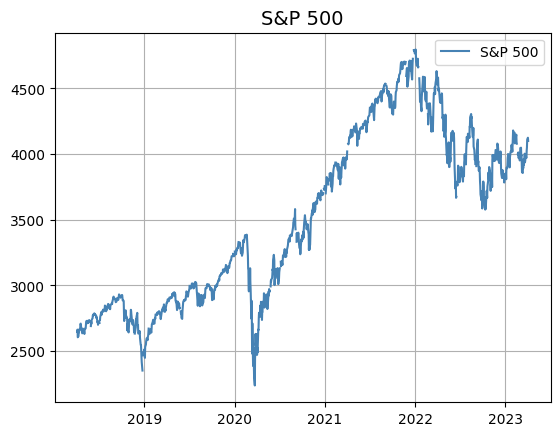

In [4]:
standard     = PlotStyle(color="steelblue", tick_size=10, title_size=14)

fig, ax = plt.subplots()

standard.plot(
    ax,
    portfolios["date"],
    portfolios["sp500"],
    "S&P 500",
    "S&P 500"
)

<font size = "5">

Example 2: An orange layout we call ``presentation''

- ```PlotStyle``` is the class (a template or blueprint)
- ```presentation``` is a particular instance of that class
- ```plot``` is a self-referential function defined as part of the class

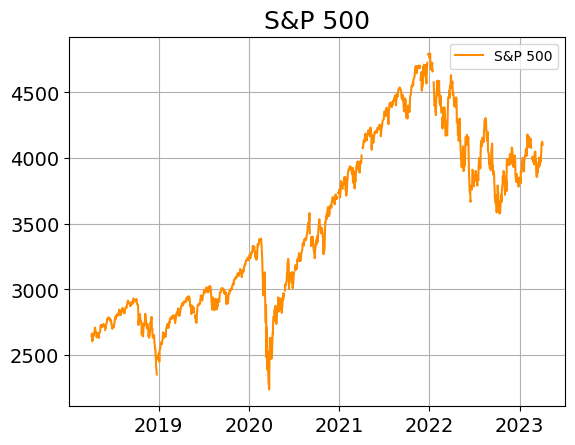

In [5]:
presentation = PlotStyle(color="darkorange", tick_size=14, title_size=18)

fig, ax = plt.subplots()
presentation.plot(
    ax,
    portfolios["date"],
    portfolios["sp500"],
    "S&P 500",
    "S&P 500"
)


<font size = "5">

Try it yourself! <br>

Configure your own instance to generate a variant of the graph above <br>
from the class - ```PlotStyle```.

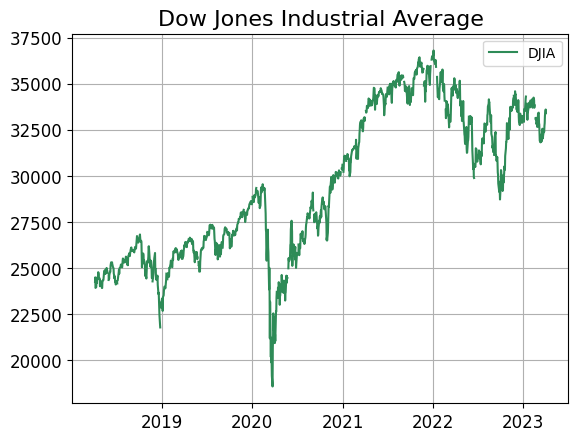

In [7]:
# Try it yourself: create a custom plot style
custom = PlotStyle(color="seagreen", tick_size=12, title_size=16, grid=True)

fig, ax = plt.subplots()
custom.plot(
    ax,
    portfolios["date"],
    portfolios["djia"],
    "Dow Jones Industrial Average",
    "DJIA"
)



